# Heart Disease Prediction System (Cleveland Dataset)

## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Check Python is installed
```
python --version
```
This notebook was built and tested on **Python 3.10**. Any Python 3.9-3.12 should work.

### 2. Create a virtual environment
A virtual environment keeps this project's packages separate from the rest of your system.

**Windows (Command Prompt / PowerShell):**
```
python -m venv venv
```

**macOS / Linux:**
```
python3 -m venv venv
```

### 3. Activate the virtual environment
You must do this every time you open a new terminal to work on this project.

**Windows (Command Prompt):**
```
venv\Scripts\activate.bat
```

**Windows (PowerShell):**
```
venv\Scripts\Activate.ps1
```
*(If PowerShell blocks this with an execution-policy error, run once: `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`)*

**macOS / Linux:**
```
source venv/bin/activate
```

Your terminal prompt should now show `(venv)` at the start of the line.

### 4. Install the required packages
This project ships a `requirements.txt` file listing the exact package versions it was built and tested with.
```
pip install -r requirements.txt
```

### 5. Register the virtual environment as a Jupyter kernel (recommended)
```
python -m ipykernel install --user --name=heart-disease-venv --display-name "Python (heart-disease-venv)"
```
When you open the notebook, make sure **Kernel -> Change Kernel -> Python (heart-disease-venv)** is selected, so it uses the packages you just installed.

### 6. Launch Jupyter Notebook
```
jupyter notebook
```
This opens Jupyter in your browser. Click this `.ipynb` file to open it, then run all cells from the top (**Kernel -> Restart & Run All**).

### 7. When you're done
Deactivate the virtual environment with:
```
deactivate
```

---

## Update Notes (this version)
This notebook is the original Titanic Passenger Survival notebook, adapted to the **Cleveland Heart Disease dataset** (`processed_cleveland.data`). The overall flow (Steps 1-10) and coding style are unchanged. Only the dataset-specific parts were modified:
- Step 2 now reads `processed_cleveland.data` (the file has no header row, so the 14 column names are given in the code, and `?` is read as a missing value)
- Step 3.2 now has real pre-processing: the 6 rows with missing values (in `ca` and `thal`) are removed, and the original 0-4 `num` column is converted into a Yes/No `HeartDisease` output
- Step 5 label-encodes only the output (`HeartDisease`); the 13 input attributes are already numeric
- Steps 6.2, 6.4, 7.1 and 8.3 add one extra idea: the inputs are scaled with `StandardScaler`. This is needed because columns such as `chol` and `thalach` have much larger values than columns such as `sex` or `fbs`; without scaling the SVC performs at about chance level on this dataset
- Steps 8 and 9 use heart disease inputs and examples

The modelling approach is unchanged: Support Vector Classifier (SVC), the same train/test split style, and the same accuracy / precision / recall / F1 / confusion matrix evaluation.

## SU Meta Description
<p>
Discover the Heart Disease Prediction System, a machine learning model that analyzes patient medical measurements from the Cleveland dataset to predict whether heart disease is present.
</p>

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) using medical attributes (e.g., age, sex, chest pain type, cholesterol, maximum heart rate, etc.)
##### **Application** It is mainly used for learning data science, testing ML algorithms, and gaining insights into factors related to heart disease such as chest pain type and exercise-induced angina. It is a learning project and is **not** a medical diagnosis tool.

##  Input and Output

###  Inputs (Features / Attributes)

The data file has no header row. The names and meanings below follow the standard UCI Cleveland Heart Disease documentation, and the possible values are the ones found in the uploaded file.

| **Input Feature/Attribute**  |      **Possible Values**          |
| ------------ | ---------------------------------- |
| **age**      | Age in years (29 to 77)            |
| **sex**      | 1 = Male, 0 = Female               |
| **cp**       | Chest pain type: 1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic |
| **trestbps** | Resting blood pressure in mm Hg (94 to 200) |
| **chol**     | Serum cholesterol in mg/dl (126 to 564) |
| **fbs**      | Fasting blood sugar > 120 mg/dl: 1 = True, 0 = False |
| **restecg**  | Resting ECG result: 0 = Normal, 1 = ST-T wave abnormality, 2 = Left ventricular hypertrophy |
| **thalach**  | Maximum heart rate achieved (71 to 202) |
| **exang**    | Exercise-induced angina: 1 = Yes, 0 = No |
| **oldpeak**  | ST depression induced by exercise relative to rest (0.0 to 6.2) |
| **slope**    | Slope of the peak exercise ST segment: 1 = Upsloping, 2 = Flat, 3 = Downsloping |
| **ca**       | Number of major vessels coloured by fluoroscopy (0 to 3) |
| **thal**     | 3 = Normal, 6 = Fixed defect, 7 = Reversible defect |

### Output (Prediction)

| **Output Attribute** | **Possbile Values** |
| -------------------- | ------------------------- |
| **HeartDisease**     | Yes, No                   |

The original file stores the output in a column called `num` (0 = no heart disease, 1 to 4 = heart disease present). In Step 3.2 it is converted into `HeartDisease`: **No** for 0 and **Yes** for 1, 2, 3 and 4.

### Examples (Cleveland Heart Disease Dataset)

| age | sex | cp | trestbps | chol | fbs | restecg | thalach | exang | oldpeak | slope | ca | thal | HeartDisease |
| :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: | :----: |
| 63 | 1 | 1 | 145 | 233 | 1 | 2 | 150 | 0 | 2.3 | 3 | 0 | 6 | No |
| 67 | 1 | 4 | 160 | 286 | 0 | 2 | 108 | 1 | 1.5 | 2 | 3 | 3 | Yes |
| 67 | 1 | 4 | 120 | 229 | 0 | 2 | 129 | 1 | 2.6 | 2 | 2 | 7 | Yes |
| 37 | 1 | 3 | 130 | 250 | 0 | 0 | 187 | 0 | 3.5 | 3 | 0 | 3 | No |
| 41 | 0 | 2 | 130 | 204 | 0 | 2 | 172 | 0 | 1.4 | 1 | 0 | 3 | No |

## Developer & System Information

|                                |                                                                                         |
| ------------------------------------------- | --------------------------------------------------------------------------------------------------- |
| **Developer Name**                          | Mr. Mohsin Afzal, Dr. Rao Muhammad Adeel Nawab                                                      |
| **LinkedIn** (Mohsin Afzal)                 | [Mohsin Afzal](https://www.linkedin.com/in/mohsin-mahmood-7a2139347/)                               |
| **LinkedIn** (Dr. Rao Muhammad Adeel Nawab) | [Dr. Rao Muhammad Adeel Nawab](https://www.linkedin.com/in/rao-muhammad-adeel-nawab/)               |
| **Program Name**                            | heart\_disease\_project                                                                                    |
| **IDE**                                     | Jupyter Notebook                                                                                    |
| **Programming Language**                    | Python 3.13.5                                                                                       |
| **Operating System**                        | Windows 11                                                                                          |
| **Libraries**                               | NumPy 2.1.3, Pandas 2.2.3, Pickle (built-in), scikit-learn 1.6.1, PrettyTable 3.16.0, Matplotlib, Seaborn |
| **Date of Completion**                      | 9-Sep-2025                                                                                          |
| **Website**                                 | [ilmoirfan.ai](https://ilmoirfan.ai), [ilmoirfan.com](https://ilmoirfan.com)                        |
| **Email**                                   | [info@ilmoirfan.ai](mailto:info@ilmoirfan.ai), [info@ilmoirfan.com](mailto:info@ilmoirfan.com)      |

##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data (Missing Values and Output Conversion)
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data (Output is converted in Numeric Representation, Input is already Numeric)
  - Step 5.1: Train the Label Encoder (for the Output)
  - Step 5.2: Label Encode the Output
  - Step 5.3: Prepare the Input (already Numeric)
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data (and Scaling the Inputs)
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model and the Scaler
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data (Scaling with the Saved Scaler)
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - **Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) — NEW**
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Scaling of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- **Step 10: Deploy Your Model as a Public Web App (NEW)**
  - Step 10.1: Why Deploy a Model?
  - Step 10.2: Create a GitHub Account and Repository
  - Step 10.3: Write a Simple Web App
  - Step 10.4: Create a Streamlit Community Cloud Account
  - Step 10.5: Deploy Your App
  - Step 10.6: Troubleshooting Common Issues
  - Step 10.7: Share Your Live Link

## Code – Heart Disease Prediction

###  Step 1: Import Libraries

In [9]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import StandardScaler (used to bring all numeric inputs to a similar scale)
from sklearn.preprocessing import StandardScaler

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [10]:
"""
Purpose of this section:
-------------------------
This part of the code loads the Cleveland Heart Disease dataset from the
data file into a pandas DataFrame. The file has no header row, so the
column names are given in the code. A "?" in the file means the value is
missing, so it is read as NaN. It then displays the dataset so that
students can see the raw data being used for further processing and
model training.
"""

# Names of the 14 columns in the data file (the file itself has no header row)
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Read the data file and load it into a pandas DataFrame
# 'processed_cleveland.data' should be present in the working directory
sample_data = pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\heart\processed.cleveland.data", header=None, names=column_names, na_values="?")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)



Sample Data:

      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0    63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1    67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2    67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3    37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4    41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5    56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6    62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7    57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8    63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9    53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   
10   57.0  1.0  4.0     140.0  192.0  0.0      0.0    148.0    0.0      0.4   
11   56.0  0.0  2.0     140.0  294.0

### Step 3: Understand and Pre-process Sample Data

####  Step 3.1: Understand Sample Data

In [11]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(sample_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", sample_data["age"].count())
print("========================================\n")



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


Number of Instances in Sample Data: 303



#### Step 3.2: Pre-process Sample Data
o   Rows with missing values (the `?` entries in `ca` and `thal`) are removed
o   The output column `num` (0 to 4) is converted into `HeartDisease` (No / Yes)

In [12]:
"""
Purpose of this section:
-------------------------
Unlike the Titanic sample data, the heart disease data needs a little
pre-processing:
1. Rows with missing values (the "?" entries, now NaN) are removed.
2. The output column "num" holds 0 (no heart disease) and 1, 2, 3, 4
   (heart disease present). To keep this a Yes/No classification task,
   exactly like "Survived" in the Titanic notebook, it is converted into
   a new column "HeartDisease": No (num = 0) or Yes (num = 1 to 4).
"""

# Show how many values are missing in each attribute
print("\n\nMissing Values in Each Attribute:")
print("=================================\n")
print(sample_data.isnull().sum())

# Remove the rows that contain missing values
sample_data = sample_data.dropna().reset_index(drop=True)

# Show the original values of "num" (after removing the missing rows)
print("\n\nValues of num (0 = No Heart Disease, 1-4 = Heart Disease):")
print("==========================================================\n")
print(sample_data["num"].value_counts().sort_index())

# Convert "num" into the Yes/No output "HeartDisease" and remove "num"
sample_data["HeartDisease"] = np.where(sample_data["num"] == 0, "No", "Yes")
sample_data = sample_data.drop(columns=["num"])

print("\n\nNumber of Instances After Pre-processing:", sample_data["age"].count())
print("========================================\n")
print(sample_data["HeartDisease"].value_counts())



Missing Values in Each Attribute:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Values of num (0 = No Heart Disease, 1-4 = Heart Disease):

num
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64


Number of Instances After Pre-processing: 297

HeartDisease
No     160
Yes    137
Name: count, dtype: int64


#### Step 4: Feature Extraction
o   Features are already Extracted
o   No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Output is converted in Numeric Representation, Input is already Numeric)

#### Step 5.1: Train the Label Encoder (for the Output)

In [13]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains a Label Encoder.
Label Encoding is used to convert categorical values (like 'Yes', 'No')
into numeric codes that machine learning algorithms can work with.

In the heart disease data, only the output ("HeartDisease") contains text.
The 13 input attributes are already numeric, so they do not need encoders.

Steps:
1. Define the label categories of the output.
2. Initialize a LabelEncoder for the output.
3. Train (fit) the LabelEncoder with its category values.
"""

# Define label categories of the output
# These are the possible values the column can have in the dataset
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create the LabelEncoder object for the output column
heart_disease_label_encoder = LabelEncoder()

# Train (fit) the encoder on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
heart_disease_label_encoder.fit(np.ravel(heart_disease))

Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[object](2,)","['No','Yes']"


#### Step 5.2: Label Encode the Output

In [14]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("HeartDisease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data["encoded_heartdisease"] = heart_disease_label_encoder.transform(sample_data['HeartDisease'])

# Show original "HeartDisease" values and their numeric encodings
print(sample_data[["HeartDisease", "encoded_heartdisease"]])

# Replace the original categorical output column with encoded values for the output dataset
sample_data_encoded_output['HeartDisease'] = sample_data['encoded_heartdisease']

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r'sample-data-encoded-output.csv', index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

    HeartDisease  encoded_heartdisease
0             No                     0
1            Yes                     1
2            Yes                     1
3             No                     0
4             No                     0
5             No                     0
6            Yes                     1
7             No                     0
8            Yes                     1
9            Yes                     1
10            No                     0
11            No                     0
12           Yes                     1
13            No                     0
14            No                     0
15            No                     0
16           Yes                     1
17            No                     0
18            No                     0
19            No                     0
20            No                     0
21            No                     0
22           Yes                     1
23           Yes

#### Step 5.3: Prepare the Input (already Numeric)

In [15]:
"""
Purpose of this section:
-------------------------
In the Titanic notebook, the text inputs (PClass, Gender, etc.) were Label
Encoded here. In the heart disease data, all 13 input attributes
("age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
"exang", "oldpeak", "slope", "ca", "thal") are already numeric, so no
encoding is needed. This part of the code only prepares the final encoded
dataset (numeric inputs + encoded output) that is used for training.
"""

# Create a copy of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Print encoded dataset (inputs are already numeric, output is now 0/1)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r'sample-data-encoded.csv', index=False, header=True)



Sample Data after Label Encoding:

      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0    63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1    67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2    67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3    37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4    41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5    56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6    62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7    57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8    63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9    53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   
10   57.0  1.0  4.0     140.0  192.0  0.0      0.0    148.0    0.0      0.4   
11   56.0  0.0 

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [16]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=False keeps the original order of rows (no shuffling before splitting)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r'training-data-encoded.csv', index=False, header=True)
testing_data_encoded.to_csv(r'testing-data-encoded.csv', index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)


Training Data shape: (237, 14)
Testing Data shape: (60, 14)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data (and Scaling the Inputs)

In [17]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.

It also scales the input vectors with a StandardScaler. The heart disease
attributes have very different ranges (for example "chol" goes up to 564,
while "sex" is only 0 or 1). Without scaling, the large-valued attributes
dominate the Support Vector Classifier. The scaler learns its values from
the training data only.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

# Scale the input vectors (fit on training data only)
scaler = StandardScaler()
input_vector_train = pd.DataFrame(
    scaler.fit_transform(input_vector_train),
    columns=input_vector_train.columns
)

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 13)
Output labels (train) shape: (237,)


### 6.3: Train the Support Vector Classifier

In [18]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., heart disease vs. no heart disease).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma='auto', random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model and the Scaler

In [19]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model and the trained scaler to your computer so they can be reused later
without retraining.
"""

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print("Saved: svc_trained_model.pkl")

# Save the trained scaler to a file named "scaler.pkl"
pickle.dump(scaler, open('scaler.pkl', 'wb'))
print("Saved: scaler.pkl")

Saved: svc_trained_model.pkl
Saved: scaler.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data (Scaling with the Saved Scaler)

In [20]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.

The input vectors are scaled with the scaler that was saved during training
(the test data must be scaled exactly like the training data).
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

# Load the saved scaler and scale the test input vectors
scaler = pickle.load(open('scaler.pkl', 'rb'))
input_vector_test = pd.DataFrame(
    scaler.transform(input_vector_test),
    columns=input_vector_test.columns
)

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 13)
Output labels (test) shape: (60,)


### Step 7.2: Load the Saved Model

In [21]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print("Model loaded from svc_trained_model.pkl")


Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [22]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r'model-predictions.csv', index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)




Predictions Returned by svc_trained_model:



      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
237  41.0  1.0  2.0     110.0  235.0  0.0      0.0    153.0    0.0      0.0   
238  41.0  0.0  2.0     126.0  306.0  0.0      0.0    163.0    0.0      0.0   
239  49.0  0.0  4.0     130.0  269.0  0.0      0.0    163.0    0.0      0.0   
240  61.0  1.0  1.0     134.0  234.0  0.0      0.0    145.0    0.0      2.6   
241  60.0  0.0  3.0     120.0  178.0  1.0      0.0     96.0    0.0      0.0   
242  67.0  1.0  4.0     120.0  237.0  0.0      0.0     71.0    0.0      1.0   
243  58.0  1.0  4.0     100.0  234.0  0.0      0.0    156.0    0.0      0.1   
244  47.0  1.0  4.0     110.0  275.0  0.0      2.0    118.0    1.0      1.0   
245  52.0  1.0  4.0     125.0  212.0  0.0      0.0    168.0    0.0      1.0   
246  62.0  1.0  2.0     128.0  208.0  1.0      2.0    140.0    0.0      0.0   
247  57.0  1.0  4.0     110.0  201.0  0.0      0.0    126.0    1.0      1.5   
248  58.0  1.0  4.0     146.0  218.0  0.0      0.0  

### Step 7.4: Calculate the Accuracy Score

In [23]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.69      0.86      0.77        29
   Heart Disease (1)       0.83      0.65      0.73        31

            accuracy                           0.75        60
           macro avg       0.76      0.75      0.75        60
        weighted avg       0.77      0.75      0.75        60


Confusion Matrix:

                          Predicted: No Heart Disease  \
Actual: No Heart Disease                           25   
Actual: Heart Disease                              11   

                          Predicted: Heart Disease  
Actual: No Heart Disease                         4  
Actual: Heart Disease                           20  


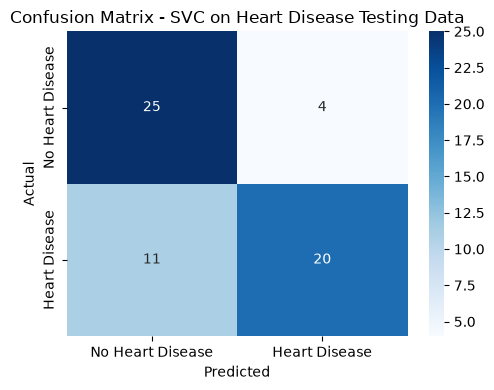

In [24]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small or imbalanced
datasets. This section adds the standard classification metrics:
- Precision: of everyone the model predicted as "Heart Disease", how many actually had it?
- Recall: of everyone who actually had heart disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Heart Disease', 'Heart Disease'],
            yticklabels=['No Heart Disease', 'Heart Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [25]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(the 13 attributes: age, sex, cp, trestbps, chol, fbs, restecg, thalach,
exang, oldpeak, slope, ca, thal). In an interactive Jupyter session,
running this cell will prompt you for input(). For this notebook copy,
we pre-fill a demo patient so the notebook can also be read/run
top-to-bottom without needing to type anything.

To try your own values interactively, replace the 13 lines below with:
    age_input = float(input("Please enter Age in years here (e.g. 58): ").strip())
    sex_input = float(input("Please enter Sex here (1 = Male, 0 = Female): ").strip())
    cp_input = float(input("Please enter Chest Pain Type here (1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic): ").strip())
    trestbps_input = float(input("Please enter Resting Blood Pressure here (mm Hg): ").strip())
    chol_input = float(input("Please enter Serum Cholesterol here (mg/dl): ").strip())
    fbs_input = float(input("Please enter Fasting Blood Sugar > 120 mg/dl here (1 = True, 0 = False): ").strip())
    restecg_input = float(input("Please enter Resting ECG Result here (0, 1, 2): ").strip())
    thalach_input = float(input("Please enter Maximum Heart Rate here: ").strip())
    exang_input = float(input("Please enter Exercise Induced Angina here (1 = Yes, 0 = No): ").strip())
    oldpeak_input = float(input("Please enter ST Depression (oldpeak) here (e.g. 1.5): ").strip())
    slope_input = float(input("Please enter Slope of Peak Exercise ST Segment here (1, 2, 3): ").strip())
    ca_input = float(input("Please enter Number of Major Vessels here (0, 1, 2, 3): ").strip())
    thal_input = float(input("Please enter Thal here (3 = Normal, 6 = Fixed defect, 7 = Reversible defect): ").strip())
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
age_input = 58
sex_input = 1
cp_input = 4
trestbps_input = 130
chol_input = 250
fbs_input = 0
restecg_input = 0
thalach_input = 120
exang_input = 1
oldpeak_input = 1.5
slope_input = 2
ca_input = 0
thal_input = 7

print(f"age: {age_input}, sex: {sex_input}, cp: {cp_input}, trestbps: {trestbps_input}, chol: {chol_input}, "
      f"fbs: {fbs_input}, restecg: {restecg_input}, thalach: {thalach_input}, exang: {exang_input}, "
      f"oldpeak: {oldpeak_input}, slope: {slope_input}, ca: {ca_input}, thal: {thal_input}")

age: 58, sex: 1, cp: 4, trestbps: 130, chol: 250, fbs: 0, restecg: 0, thalach: 120, exang: 1, oldpeak: 1.5, slope: 2, ca: 0, thal: 7


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [26]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input
and converts it into a structured feature vector (DataFrame).
The columns must be in exactly the same order as in the sample data.
"""

user_input = pd.DataFrame({
    'age': [age_input],
    'sex': [sex_input],
    'cp': [cp_input],
    'trestbps': [trestbps_input],
    'chol': [chol_input],
    'fbs': [fbs_input],
    'restecg': [restecg_input],
    'thalach': [thalach_input],
    'exang': [exang_input],
    'oldpeak': [oldpeak_input],
    'slope': [slope_input],
    'ca': [ca_input],
    'thal': [thal_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   58    1   4       130   250    0        0      120      1      1.5      2   

   ca  thal  
0   0     7  


### Step 8.3: Scaling of Feature Vector (Exactly Same as Scaled Feature Vectors of Sample Data)

In [27]:
"""
Purpose of this section:
-------------------------
The input attributes are already numeric, so no Label Encoding is needed
(in the Titanic notebook the LabelEncoders were used here). This part of
the code scales the user's input with the previously saved scaler, in
exactly the same way as the training and testing data were scaled.
"""

scaler = pickle.load(open('scaler.pkl', 'rb'))

unseen_data_features = pd.DataFrame(
    scaler.transform(user_input),
    columns=user_input.columns
)

print("\n\nUser Input Scaled Feature Vector:")
print("=================================\n")
print(unseen_data_features)



User Input Scaled Feature Vector:

        age       sex        cp  trestbps      chol       fbs   restecg  \
0  0.408966  0.687059  0.876292 -0.099058 -0.026642 -0.423207 -1.099909   

    thalach     exang   oldpeak     slope        ca      thal  
0 -1.372033  1.374861  0.366736  0.634123 -0.712395  1.154433  


### Step 8.4: Load the Saved Model

In [28]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

model = pickle.load(open('svc_trained_model.pkl', 'rb'))


### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [29]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a new patient (user input) has heart disease or not.
"""

predicted_heart_disease = model.predict(unseen_data_features)

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE PRESENT"
if predicted_heart_disease == 0:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|     HEART DISEASE PRESENT      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [30]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert reviewing
this model's predictions on a few cases. (These comments are illustrative
examples for teaching purposes, not real expert reviews.)
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Domain Expert (Cardiology)", "Student Tester"],
    "Case": [
        "Male, chest pain type 4, exercise-induced angina, thal 7 -> predicted HEART DISEASE PRESENT",
        "Female, chest pain type 2, no exercise-induced angina, thal 3 -> predicted NO HEART DISEASE",
        "Test set: 31 patients with heart disease, but 11 were predicted as NO HEART DISEASE",
    ],
    "Feedback": [
        "Plausible: in this dataset about 73% of patients with chest pain type 4 and about 76% of those with exercise-induced angina had heart disease.",
        "Plausible: in this dataset only about 23% of patients with thal = 3 had heart disease.",
        "Concerning: missing a patient who has heart disease is worse than a false alarm. Recall for heart disease (0.65) needs to improve, and the 60-row test set is small.",
    ],
})
print(example_feedback.to_string(index=False))

                  Reviewer                                                                                        Case                                                                                                                                                             Feedback
Domain Expert (Cardiology) Male, chest pain type 4, exercise-induced angina, thal 7 -> predicted HEART DISEASE PRESENT                       Plausible: in this dataset about 73% of patients with chest pain type 4 and about 76% of those with exercise-induced angina had heart disease.
Domain Expert (Cardiology) Female, chest pain type 2, no exercise-induced angina, thal 3 -> predicted NO HEART DISEASE                                                                               Plausible: in this dataset only about 23% of patients with thal = 3 had heart disease.
            Student Tester         Test set: 31 patients with heart disease, but 11 were predicted as NO HEART DISEASE Concerning: missing a patient

#### Step 9.2: Make a List of Potential Improvements

In [31]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Use more data - only 297 usable rows (60 in the test set) are available, so the results can change a lot with a different split",
    "Improve recall for heart disease, because missing a sick patient is more costly than a false alarm",
    "Fill in the missing ca and thal values instead of removing the 6 rows that contain them",
    "Try cross-validated evaluation, and compare additional models (e.g. Logistic Regression, Decision Tree, Random Forest) beyond SVC",
    "Try the original 5-level num output (0 to 4) to predict the severity of heart disease instead of only Yes/No",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more data - only 297 usable rows (60 in the test set) are available, so the results can change a lot with a different split
2. Improve recall for heart disease, because missing a sick patient is more costly than a false alarm
3. Fill in the missing ca and thal values instead of removing the 6 rows that contain them
4. Try cross-validated evaluation, and compare additional models (e.g. Logistic Regression, Decision Tree, Random Forest) beyond SVC
5. Try the original 5-level num output (0 to 4) to predict the severity of heart disease instead of only Yes/No


#### Step 9.3: Improve the Model Based on Feedback

In [32]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the improvements listed above and re-run Steps 6-7 to confirm
the new model's recall and accuracy improve before replacing the deployed model.
"""

print("Next version: retrain with cross-validation and compare more models, aiming for higher recall on heart disease, then re-evaluate before replacing svc_trained_model.pkl and scaler.pkl")

Next version: retrain with cross-validation and compare more models, aiming for higher recall on heart disease, then re-evaluate before replacing svc_trained_model.pkl and scaler.pkl


## Step 10: Deploy Your Model as a Public Web App (NEW)

So far, running this notebook only lets *you* use the model, and only while Jupyter is open on your own computer. This section shows how to turn it into a **live website** anyone can open in a browser - no Python, no Jupyter, nothing installed on their end. This is the standard process for sharing a notebook model as a live demo.

#### Step 10.1: Why Deploy a Model?

A trained model is only useful if people other than you can access it. Deploying it as a small web app is how data scientists share results with non-technical stakeholders (teachers, classmates, clients) who won't run a notebook themselves.

#### Step 10.2: Create a GitHub Account and Repository

1. If you don't have one, sign up for a free account at **https://github.com**.
2. Create a new repository (click the **+** icon top-right -> **New repository**). Give it a name (e.g. `my-heart-disease-app`), keep it **Public**, and click **Create repository**.
3. Upload your notebook's folder to this repository. The easiest way from a browser: open your new repo -> **Add file -> Upload files** -> drag in your project folder's contents (at minimum you need `app.py`, `requirements.txt`, and your trained `.pkl` model file and `scaler.pkl` - see Step 10.3).
   - Alternatively, if you're comfortable with git on the command line:
     ```
     git init
     git add .
     git commit -m "Initial commit"
     git branch -M main
     git remote add origin https://github.com/<your-username>/my-heart-disease-app.git
     git push -u origin main
     ```

#### Step 10.3: Write a Simple Web App

You need a small Python script that loads your saved model and lets a user enter inputs through a web form. **Streamlit** is a beginner-friendly library for this - it turns a plain Python script into a web app with almost no HTML/CSS needed.

You will need to write an `app.py` for this project with one input field for each of the 13 attributes (see the Input table at the top of this notebook). At minimum, your `app.py` needs to:
1. Load your trained model with `pickle.load(...)`.
2. Load `scaler.pkl` (saved in Step 6.4) and apply it to the user's inputs in the same way as Step 8.3.
3. Use Streamlit widgets (`st.selectbox`, `st.number_input`, etc.) to collect input from the user.
4. Call `model.predict(...)` on a button click and display the result with `st.success(...)` / `st.error(...)`.

You also need a `requirements.txt` in the **same folder** as `app.py`, listing the packages your app needs, for example:
```
streamlit
scikit-learn
pandas
numpy
```

#### Step 10.4: Create a Streamlit Community Cloud Account

1. Go to **https://share.streamlit.io**.
2. Click **Sign up** / **Sign in with GitHub** and authorize Streamlit to access your GitHub repositories. This is free for public apps.

#### Step 10.5: Deploy Your App

1. On the Streamlit Cloud dashboard, click **Create app** -> **Deploy a public app from GitHub**.
2. Fill in:
   - **Repository:** `<your-username>/my-heart-disease-app`
   - **Branch:** `main`
   - **Main file path:** `app.py` (or `streamlit-app/app.py` if it's inside a subfolder, like in this repo)
3. Click **Deploy**. The first deploy takes a minute or two while it installs your `requirements.txt`.
4. You'll get a public URL like `https://<something>.streamlit.app` - this is your live app. Share it with anyone!

#### Step 10.6: Troubleshooting Common Issues

These are real issues encountered while deploying the original Titanic demo app - check here first if your app fails:

- **`ModuleNotFoundError` for a package that's clearly in `requirements.txt`:** This usually means the deployment's default Python version doesn't have a prebuilt package ("wheel") for one of your pinned versions (this happened here when Streamlit Cloud defaulted to a very new Python 3.14, which didn't yet have scikit-learn wheels available). **Fix:** open your app's **Settings -> General -> Python version** in the Streamlit Cloud dashboard, and pick a stable version like **3.11** or **3.12**, then save (it will reboot automatically).
- **App stuck on "Your app is in the oven" for a very long time:** This usually means it's stuck retrying after a crash, not still building normally (a normal build finishes in a few minutes). **Fix:** open the app, click **Manage app** (bottom-right) to see the live build log, check for red error lines, fix the underlying `requirements.txt`/Python version issue, then use the reboot option in that same log panel.
- **`requirements.txt` seems to be ignored:** Make sure it's in the exact same folder as your main app file (`app.py`), not just somewhere in the repo.

#### Step 10.7: Share Your Live Link

Once deployed, add the link to your notebook, your GitHub repo's `README.md`, or send it directly to whoever you want to try your model - they just click and use it, with nothing to install.

---

## Conclusion
The analysis shows that the Cleveland heart disease data can be used to predict whether heart disease is present from 13 medical attributes. In the dataset, chest pain type, exercise-induced angina and the thal result are clearly linked to heart disease (for example, about 73% of patients with chest pain type 4 had heart disease). The Support Vector Classifier achieved an accuracy of 0.75 on the held-out test set. It is better at avoiding false alarms (precision 0.83 for heart disease) than at catching every sick patient (recall 0.65 for heart disease, see Step 7.5), which is the weak point to improve first. Because the dataset is small (297 usable rows, 60 in the test set), these numbers are only a learning example and the model must not be used for real medical diagnosis.